# Are human voting patterns different from machine voting patterns?

The independent comparison is the human vote versus the four machine votes. The recorded `group` result is analyzed separately because it includes the human vote. Explicit imposter identity was not stored, so general voting accuracy is out of scope; correctness is known only for the small subset where the recorded group caught the imposter.

In [1]:
from collections import Counter
from itertools import combinations
from pathlib import Path
import json, math, re, sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
from scipy.stats import beta
from sklearn.feature_extraction.text import TfidfVectorizer

for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    if (candidate / 'experiments' / 'datasets' / 'human_behavior_manifest.json').exists():
        ROOT = candidate; break
else: raise FileNotFoundError('Repository root not found')
NOTEBOOK_DIR = ROOT / 'experiments' / 'notebooks' / 'human_vs_machine'
sys.path.insert(0, str(NOTEBOOK_DIR))
from notebook_utils import cluster_bootstrap_difference, cosine_distance, ollama_embeddings, save_json
SEED, SAVE_ARTIFACTS, RUN_OLLAMA = 20260805, True, True
RESULTS_DIR = NOTEBOOK_DIR / 'results' / 'voting'
DATASETS = ROOT / 'experiments' / 'datasets'
MANIFEST = json.loads((DATASETS / 'human_behavior_manifest.json').read_text())
patterns = pd.read_csv(DATASETS / 'human_voting_patterns.csv', keep_default_na=False)
clues = pd.read_csv(DATASETS / 'human_machine_clues.csv', keep_default_na=False)
round_payloads = [json.loads(line) for line in (DATASETS / 'human_behavior_rounds.jsonl').read_text().splitlines()]
raw_votes = pd.DataFrame([vote for payload in round_payloads for vote in payload['votes']])
assert len(patterns) == MANIFEST['counts']['complete_voting_rounds'] == 29
plt.style.use('default')


## Machine-vote reconstruction and validation

In [2]:
voting_round_ids = set(patterns.round_id)
votes = raw_votes[raw_votes.round_id.isin(voting_round_ids)].copy()
machine_votes = votes[~votes.voter_id.isin(['human', 'group'])].copy()
human_votes = votes[votes.voter_id == 'human'].set_index('round_id')
assert len(machine_votes) == 116 and machine_votes.groupby('round_id').size().eq(4).all()
reconstructed = []
for round_id, frame in machine_votes.groupby('round_id'):
    counts = Counter(frame.voted_for_id)
    highest = max(counts.values()); leaders = sorted(k for k, value in counts.items() if value == highest)
    reconstructed.append({'round_id': round_id, 'reconstructed_majority': leaders[0] if len(leaders) == 1 else '', 'machine_pattern': '-'.join(map(str, sorted(counts.values(), reverse=True))), 'machine_entropy': -sum((n / 4) * math.log2(n / 4) for n in counts.values())})
reconstructed = pd.DataFrame(reconstructed)
analysis = patterns.merge(reconstructed, on='round_id', validate='one_to_one')
assert (analysis.reconstructed_majority == analysis.machine_majority_voted_for_id).all()
assert (analysis.machine_majority_status == 'selected').sum() == 22
assert (analysis.machine_majority_status == 'tie').sum() == 7
analysis[['machine_pattern', 'machine_majority_status']].value_counts().sort_index()

machine_pattern  machine_majority_status
2-1-1            selected                    8
2-2              tie                         7
3-1              selected                   13
4                selected                    1
Name: count, dtype: int64

## Human versus machine-majority agreement

{'agreements': 6,
 'disagreements': 16,
 'decided_rounds': 22,
 'ties': 7,
 'agreement_rate': 0.2727272727272727,
 'exact_ci_95': (np.float64(0.10728924837039695),
  np.float64(0.5022212012663488))}

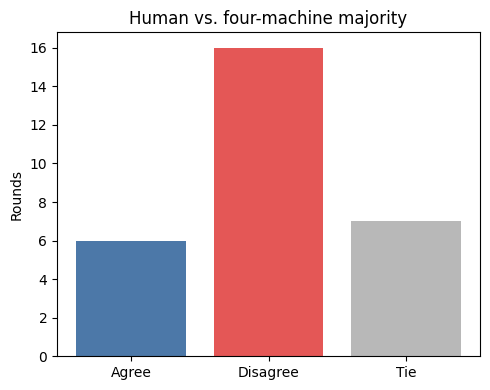

In [3]:
decided = analysis[analysis.machine_majority_status == 'selected'].copy()
agreements = decided.human_machine_majority_agree.astype(int)
successes, trials = int(agreements.sum()), len(agreements)
agreement_rate = successes / trials
exact_ci = (0.0 if successes == 0 else beta.ppf(.025, successes, trials - successes + 1), 1.0 if successes == trials else beta.ppf(.975, successes + 1, trials - successes))
agreement_summary = {'agreements': successes, 'disagreements': trials - successes, 'decided_rounds': trials, 'ties': 7, 'agreement_rate': agreement_rate, 'exact_ci_95': exact_ci}
assert (successes, trials - successes, trials) == (6, 16, 22)
fig, ax = plt.subplots(figsize=(5, 4)); ax.bar(['Agree', 'Disagree', 'Tie'], [successes, trials-successes, 7], color=['#4c78a8', '#e45756', '#b8b8b8'])
ax.set(ylabel='Rounds', title='Human vs. four-machine majority'); fig.tight_layout()
if SAVE_ARTIFACTS: RESULTS_DIR.mkdir(parents=True, exist_ok=True); fig.savefig(RESULTS_DIR / 'majority_agreement.png', dpi=160)
agreement_summary

## Consensus strength

In [4]:
consensus = analysis.groupby('machine_pattern').agg(rounds=('round_id', 'size'), decided=('machine_majority_status', lambda x: (x == 'selected').sum()), agreement_rate=('human_machine_majority_agree', lambda x: pd.to_numeric(x, errors='coerce').mean()), mean_entropy=('machine_entropy', 'mean')).reset_index()
consensus

,machine_pattern,rounds,decided,agreement_rate,mean_entropy
0,2-1-1,8,8,0.375000,1.500000
1,2-2,7,0,NaN,1.000000
2,3-1,13,13,0.230769,0.811278
3,4,1,1,0.000000,0.000000


## Human-machine versus machine-machine pairwise agreement

In [5]:
pairwise_rows = []
for round_id, frame in machine_votes.groupby('round_id'):
    machine_targets = frame.voted_for_id.tolist(); human_target = human_votes.loc[round_id, 'voted_for_id']
    human_machine = np.mean([human_target == target for target in machine_targets])
    machine_machine = np.mean([left == right for left, right in combinations(machine_targets, 2)])
    pairwise_rows.append({'round_id': round_id, 'human_machine_agreement': human_machine, 'machine_machine_agreement': machine_machine, 'difference': human_machine - machine_machine})
pairwise = pd.DataFrame(pairwise_rows)
pairwise_estimate, pairwise_low, pairwise_high = cluster_bootstrap_difference(pairwise.difference, seed=SEED)
pairwise_summary = {'human_machine_mean': pairwise.human_machine_agreement.mean(), 'machine_machine_mean': pairwise.machine_machine_agreement.mean(), 'difference': pairwise_estimate, 'ci_95': (pairwise_low, pairwise_high), 'rounds': len(pairwise)}
pairwise_summary

{'human_machine_mean': np.float64(0.25),
 'machine_machine_mean': np.float64(0.3850574712643678),
 'difference': -0.1350574712643678,
 'ci_95': (-0.2614942528735632, -0.01149425287356321),
 'rounds': 29}

## Vote dispersion

In [6]:
dispersion = analysis[['round_id', 'machine_pattern', 'machine_entropy', 'machine_unique_target_count', 'machine_leader_vote_share', 'machine_majority_status']].copy()
dispersion_summary = dispersion.groupby('machine_majority_status').agg(rounds=('round_id', 'size'), mean_entropy=('machine_entropy', 'mean'), mean_unique_targets=('machine_unique_target_count', 'mean'), mean_leader_share=('machine_leader_vote_share', 'mean'))
dispersion_summary

,rounds,mean_entropy,mean_unique_targets,mean_leader_share
machine_majority_status,,,,
selected,22,1.024846,2.318182,0.670455
tie,7,1.000000,2.000000,0.500000


## Human impact on the recorded five-vote tally

In [7]:
def human_impact(row):
    machine_selected = row.machine_majority_status == 'selected'; group_selected = row.recorded_group_status == 'selected'
    if machine_selected and row.human_voted_for_id == row.machine_majority_voted_for_id: return 'reinforces machine majority'
    if machine_selected and not group_selected: return 'creates recorded-group tie'
    if machine_selected: return 'opposes majority without changing result'
    if group_selected: return 'resolves machine tie'
    return 'preserves tie'
analysis['human_impact'] = analysis.apply(human_impact, axis=1)
impact_counts = analysis.human_impact.value_counts()
impact_counts

human_impact
opposes majority without changing result    13
reinforces machine majority                  6
resolves machine tie                         4
preserves tie                                3
creates recorded-group tie                   3
Name: count, dtype: int64

## Characteristics of human-selected and machine-selected clues

In [8]:
paired_clues = clues[clues.round_has_human == 1].copy().reset_index(drop=True)
vectors = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4)).fit_transform(paired_clues.clue).toarray()
frequency = Counter(word for clue in paired_clues.clue for word in re.findall(r"[\w'-]+", clue.casefold()))
paired_clues['lexical_unusualness'] = paired_clues.clue.map(lambda text: np.mean([1 / frequency[word] for word in re.findall(r"[\w'-]+", text.casefold())]))
paired_clues['tfidf_outlier'] = 0.0
for round_id, frame in paired_clues.groupby('round_id'):
    indices = frame.index.to_numpy(); round_vectors = vectors[indices]
    centroid = round_vectors.mean(axis=0)
    paired_clues.loc[indices, 'tfidf_outlier'] = [cosine_distance(vector, centroid) for vector in round_vectors]
feature_lookup = paired_clues.set_index(['round_id', 'player_id'])[['word_count', 'character_count', 'lexical_unusualness', 'tfidf_outlier']]
selected_rows = []
for row in decided.itertuples():
    human_features = feature_lookup.loc[(row.round_id, row.human_voted_for_id)]
    machine_features = feature_lookup.loc[(row.round_id, row.machine_majority_voted_for_id)]
    selected_rows.append({'round_id': row.round_id, **{f'{metric}_difference': human_features[metric] - machine_features[metric] for metric in feature_lookup.columns}})
selected_features = pd.DataFrame(selected_rows)
selected_feature_summary = selected_features.drop(columns='round_id').agg(['mean', 'median', 'std']).T
selected_feature_summary

,mean,median,std
word_count_difference,0.136364,0.0,0.940894
character_count_difference,0.863636,0.0,7.153391
lexical_unusualness_difference,0.003247,0.0,0.202902
tfidf_outlier_difference,-0.021431,0.0,0.087770


## Optional Nomic embedding comparison
Set `RUN_OLLAMA = True` after starting Ollama. The cell skips gracefully when the service is unavailable.

In [9]:
embedding_selection_summary = None
if RUN_OLLAMA:
    embedding_vectors = ollama_embeddings(paired_clues.clue.tolist(), cache_path=RESULTS_DIR / 'nomic_embeddings.json')
    if embedding_vectors is not None:
        paired_clues['embedding_outlier'] = 0.0
        for round_id, frame in paired_clues.groupby('round_id'):
            indices = frame.index.to_numpy(); round_vectors = embedding_vectors[indices]; centroid = round_vectors.mean(axis=0)
            paired_clues.loc[indices, 'embedding_outlier'] = [cosine_distance(vector, centroid) for vector in round_vectors]
        embedding_lookup = paired_clues.set_index(['round_id', 'player_id']).embedding_outlier
        differences = [embedding_lookup.loc[(row.round_id, row.human_voted_for_id)] - embedding_lookup.loc[(row.round_id, row.machine_majority_voted_for_id)] for row in decided.itertuples()]
        embedding_selection_summary = {'mean_difference': float(np.mean(differences)), 'rounds': len(differences)}
embedding_selection_summary

{'mean_difference': -0.018762930920632505, 'rounds': 22}

## Exploratory agent-specific diagnostics
These estimates have only 29 observations per agent and are not confirmatory.

In [10]:
human_target_by_round = human_votes.voted_for_id.to_dict()
agent_diagnostics = machine_votes.assign(agrees_with_human=lambda frame: frame.apply(lambda row: row.voted_for_id == human_target_by_round[row.round_id], axis=1), votes_for_human=lambda frame: frame.voted_for_id == 'human').groupby(['voter_id', 'voter_name']).agg(rounds=('round_id', 'size'), human_agreement_rate=('agrees_with_human', 'mean'), votes_for_human_rate=('votes_for_human', 'mean'), unique_targets=('voted_for_id', 'nunique')).reset_index()
agent_diagnostics

,voter_id,voter_name,rounds,human_agreement_rate,votes_for_human_rate,unique_targets
0,agent_a,Agent A,29,0.137931,0.103448,4
1,agent_b,Agent B,29,0.172414,0.206897,4
2,agent_c,Agent C,29,0.344828,0.241379,4
3,agent_d,Agent D,29,0.344828,0.206897,4


## Reproducible summary
No general accuracy conclusion is reported. Only five rounds expose correctness indirectly, which is too small for comparison.

In [11]:
summary = {'dataset_version': MANIFEST['dataset_version'], 'agreement': agreement_summary, 'pairwise': pairwise_summary, 'consensus': consensus.to_dict(orient='records'), 'human_impact': impact_counts.to_dict(), 'known_correctness_rounds': int((analysis.human_vote_correct != '').sum())}
assert summary['known_correctness_rounds'] == 5
if SAVE_ARTIFACTS:
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    consensus.to_csv(RESULTS_DIR / 'consensus.csv', index=False)
    pairwise.to_csv(RESULTS_DIR / 'pairwise_agreement.csv', index=False)
    selected_features.to_csv(RESULTS_DIR / 'selected_clue_features.csv', index=False)
    save_json(RESULTS_DIR / 'summary.json', summary)
summary

{'dataset_version': '20260805_151157',
 'agreement': {'agreements': 6,
  'disagreements': 16,
  'decided_rounds': 22,
  'ties': 7,
  'agreement_rate': 0.2727272727272727,
  'exact_ci_95': (np.float64(0.10728924837039695),
   np.float64(0.5022212012663488))},
 'pairwise': {'human_machine_mean': np.float64(0.25),
  'machine_machine_mean': np.float64(0.3850574712643678),
  'difference': -0.1350574712643678,
  'ci_95': (-0.2614942528735632, -0.01149425287356321),
  'rounds': 29},
 'consensus': [{'machine_pattern': '2-1-1',
   'rounds': 8,
   'decided': 8,
   'agreement_rate': 0.375,
   'mean_entropy': 1.5},
  {'machine_pattern': '2-2',
   'rounds': 7,
   'decided': 0,
   'agreement_rate': nan,
   'mean_entropy': 1.0},
  {'machine_pattern': '3-1',
   'rounds': 13,
   'decided': 13,
   'agreement_rate': 0.23076923076923078,
   'mean_entropy': 0.8112781244591327},
  {'machine_pattern': '4',
   'rounds': 1,
   'decided': 1,
   'agreement_rate': 0.0,
   'mean_entropy': 0.0}],
 'human_impact': {